<a href="https://colab.research.google.com/github/ikuto1910-jp/california-housing-analysis/blob/main/california_housing_portfolio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# California Housing — 地区の住宅価格中央値の予測
中村郁斗 | 回帰分析ポートフォリオ

## 1. 目的と評価方針
地区の収入・住宅構成・立地から、地区内の住宅価格中央値を予測する。主指標はドル単位で解釈できるMAEとし、R²と価格帯別の符号付き誤差も確認する。

元の学習記録では、最終LightGBMのテストMAEは **27,845.63ドル**、R²は **0.842**。記録上限に達した179地区では平均 **62,328.43ドルの過小予測**が残った。以下の実行セルで結果を再計算する。

### 評価の範囲
- 20,640地区を80:20でランダム分割し、学習側の5分割交差検証で設定を比較した。
- 学習の序盤に同じテストセットで単回帰・重回帰と誤差分析を行っている。完全に未参照の最終評価としては扱えず、開発履歴を踏まえた参考評価として報告する。
- 価格は500,001ドルに記録上限がある。上限地区の評価対象は記録価格であり、その上の実際の価格は復元できない。
- ランダム分割の結果であり、未観測地域や将来の住宅市場での精度は別途検証が必要である。

## 2. 実行準備
Google Colabで先頭から実行する。データ取得にインターネット接続が必要。モデル比較と置換重要度の計算には数分かかる場合がある。実行環境の違いによる数値差は、末尾に表示するライブラリのバージョンとともに確認する。

In [1]:
%pip -q install lightgbm pandas scikit-learn matplotlib seaborn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import lightgbm
from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from lightgbm import LGBMRegressor

SEED = 42
CAP = 500_001
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(url)
X = df.drop(columns="median_house_value")
y = df["median_house_value"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
# 元の実験と同じ行順で5分割する。外側の分割で既にシャッフルされている。
folds = list(KFold(n_splits=5).split(X_train))
print("全体・学習・テストの行数", len(df), len(X_train), len(X_test))

全体・学習・テストの行数 20640 16512 4128


## 3. 学習データの確認
数値列の欠損、価格分布、相関、海への近さによる価格差を確認する。相関は特徴量を単独で見た線形関係であり、採用の判断には交差検証も使う。欠損補完の中央値は各Foldの学習側で求める。

,dtype,missing,unique
longitude,float64,0,833
latitude,float64,0,845
housing_median_age,float64,0,52
total_rooms,float64,0,5470
total_bedrooms,float64,0,1816
population,float64,0,3639
households,float64,0,1706
median_income,float64,0,10932
ocean_proximity,object,0,5
median_house_value,float64,0,3675


学習側の上限地区数 786


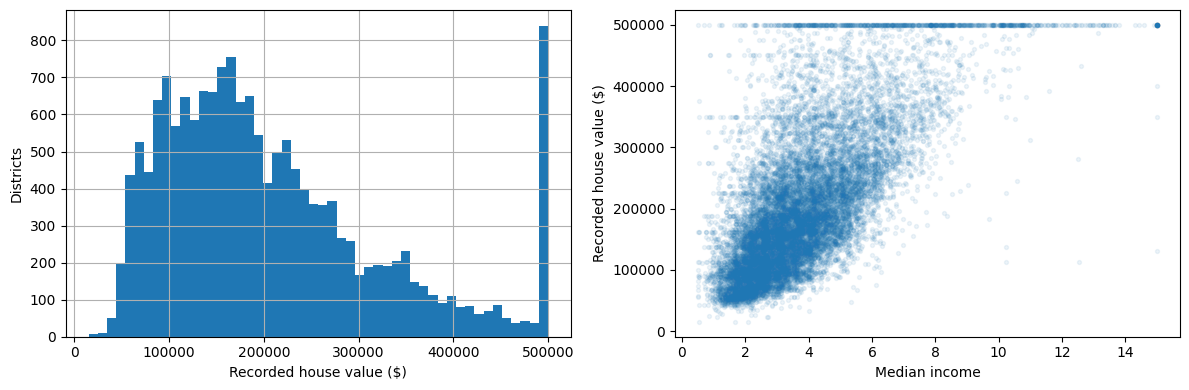

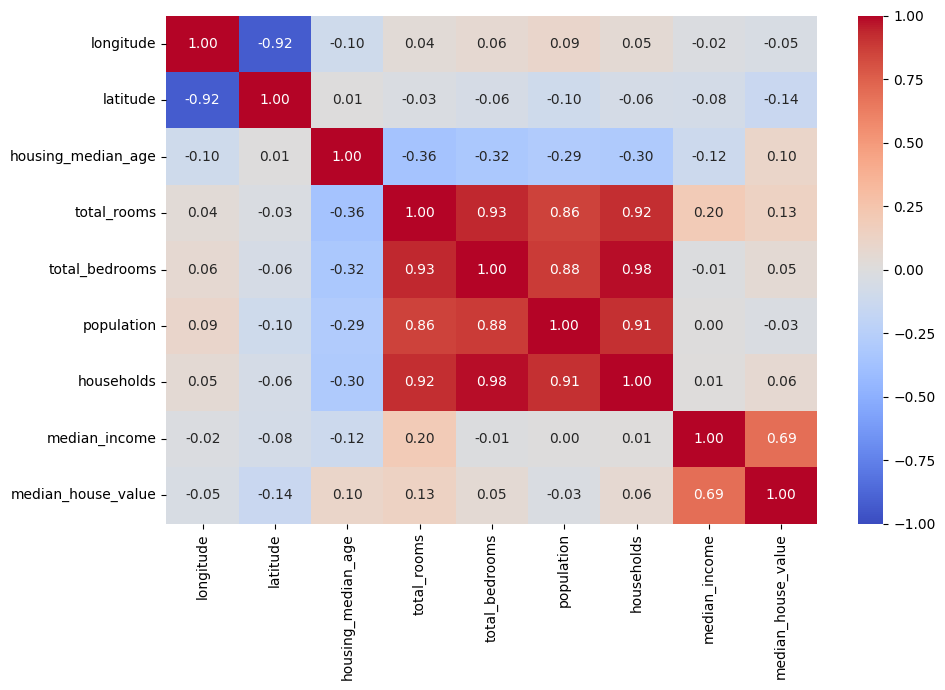

,count,median,mean
ocean_proximity,,,
<1H OCEAN,7341,215200.0,240606.09
INLAND,5227,109000.0,125163.86
ISLAND,4,357350.0,363050.00
NEAR BAY,1854,234800.0,259903.76
NEAR OCEAN,2086,228000.0,248017.34


In [3]:
train_data = X_train.assign(median_house_value=y_train)
display(pd.DataFrame({"dtype": train_data.dtypes,
                      "missing": train_data.isna().sum(),
                      "unique": train_data.nunique()}))
print("学習側の上限地区数", y_train.eq(CAP).sum())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y_train.hist(bins=50, ax=axes[0])
axes[0].set(xlabel="Recorded house value ($)", ylabel="Districts")
axes[1].scatter(X_train["median_income"], y_train, alpha=0.08, s=8)
axes[1].set(xlabel="Median income", ylabel="Recorded house value ($)")
plt.tight_layout()
plt.show()
corr = train_data.select_dtypes(include="number").corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.tight_layout()
plt.show()
display(train_data.groupby("ocean_proximity")["median_house_value"].agg(["count", "median", "mean"]).round(2))

## 4. 特徴量と前処理
部屋数・人口などの合計値には地区の規模が影響するため、世帯数や部屋数で割った比率を追加する。立地を木の分岐に使いやすくする仮説として、LA・SFまでの距離も追加した。効果は後述の比較で検証した。

比率と距離は各行の値だけで決まり、価格を使用しない。学習側・テスト側に同じ関数を適用する。分母が0以下の比率は欠損にし、Pipeline内で補完する。都市座標と地球半径は元の実験に合わせた。

In [4]:
def add_features(data):
    result = data.copy()
    households = result["households"].where(result["households"] > 0)
    rooms = result["total_rooms"].where(result["total_rooms"] > 0)
    result["rooms_per_household"] = result["total_rooms"] / households
    result["people_per_household"] = result["population"] / households
    result["bedrooms_per_room"] = result["total_bedrooms"] / rooms
    latitude = np.radians(result["latitude"])
    longitude = np.radians(result["longitude"])
    for column, city_lat, city_lon in [
        ("distance_to_la_km", 34.05, -118.24),
        ("distance_to_sf_km", 37.77, -122.42),
    ]:
        city_lat = np.radians(city_lat)
        city_lon = np.radians(city_lon)
        a = (np.sin((latitude - city_lat) / 2) ** 2
             + np.cos(latitude) * np.cos(city_lat)
             * np.sin((longitude - city_lon) / 2) ** 2)
        result[column] = 2 * 6371 * np.arcsin(np.sqrt(a.clip(0, 1)))
    return result

X_train_features = add_features(X_train)
X_test_features = add_features(X_test)
assert X_train_features.index.equals(y_train.index)
assert X_test_features.index.equals(y_test.index)
assert X_train_features.columns.equals(X_test_features.columns)

def make_preprocessor(data):
    return ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"),
         data.select_dtypes(include="number").columns),
        ("category", OneHotEncoder(drop="first", handle_unknown="ignore",
                                   sparse_output=False), ["ocean_proximity"]),
    ]).set_output(transform="pandas")

linear_model = Pipeline([
    ("preprocess", make_preprocessor(X_train)),
    ("model", LinearRegression()),
])
final_model = Pipeline([
    ("preprocess", make_preprocessor(X_train_features)),
    ("model", LGBMRegressor(objective="regression_l1", n_estimators=400,
                           learning_rate=0.1, num_leaves=63,
                           min_child_samples=50, random_state=SEED,
                           verbosity=-1, n_jobs=2)),
])

## 5. 実験履歴と選択理由
以下は元のNotebookと学習記録に残した交差検証の結果を転記したもの。段階ごとに基準モデルが異なるため、表の隣接行だけから単一の変更効果を推定しない。平均Fold MAEと全OOF予測のMAEには、Fold件数の差による微小差がある。

| 実験 | 全体MAE（ドル） | 判断 |
|---|---:|---|
| 全9特徴量の線形回帰 | 49,664.68 | 比較基準 |
| Ridge、α=0.1 | 49,664.76 | 線形回帰への改善が見られなかった |
| 元のLightGBM | 32,189.29 | 非線形モデルを採用 |
| 高価格帯の重み付け | 32,459.72 | 対象帯は改善したが、全体MAEを優先し見送り |
| 比率3列を追加 | 30,952.80 | 採用 |
| Random Forest、比率あり | 32,861.73 | LightGBMを継続 |
| 学習率0.1・400本、最小50件 | 29,627.15 | 800本の29,740.90より低い |
| 同設定に予測上限を適用 | 29,438.19 | 記録価格に合わせて採用 |
| 対数価格・二乗誤差 | 28,881.56 | 目的関数も比較 |
| ドル価格・絶対誤差 | 28,830.71 | 対数価格・絶対誤差の28,848.77も踏まえ採用 |
| 都市距離2列を追加 | 28,431.18 | 約400ドル低下、採用 |
| 葉63・最小50件 | 28,037.35 | 最終候補 |
| 葉127・最小50件 | 28,245.18 | 葉63を採用 |

### 主要モデルの交差検証を再計算
同じ学習行・5分割で中央値予測、全9特徴量の線形回帰、最終LightGBMを比較する。LightGBMには実験と同じ予測上限を適用する。

In [5]:
oof_predictions = {}
cv_rows = []
for name, model, data in [
    ("Median baseline", DummyRegressor(strategy="median"), X_train),
    ("Linear regression (9 features)", linear_model, X_train),
    ("LightGBM (14 features)", final_model, X_train_features),
]:
    predictions = cross_val_predict(model, data, y_train, cv=folds)
    if name.startswith("LightGBM"):
        predictions = predictions.clip(max=CAP)
    oof_predictions[name] = predictions
    fold_maes = [mean_absolute_error(y_train.iloc[valid], predictions[valid])
                 for _, valid in folds]
    cv_rows.append({"Model": name, "OOF MAE ($)": mean_absolute_error(y_train, predictions),
                    "Mean fold MAE ($)": np.mean(fold_maes),
                    "OOF R2": r2_score(y_train, predictions)})
display(pd.DataFrame(cv_rows).set_index("Model").round(3))

,OOF MAE ($),Mean fold MAE ($),OOF R2
Model,,,
Median baseline,88601.217,88601.203,-0.056
Linear regression (9 features),49664.688,49664.675,0.648
LightGBM (14 features),28037.351,28037.346,0.845


## 6. 特徴量重要度
検証側の1列をシャッフルし、学習済みモデルのMAE増加を測る。各Fold・各列で3回試す。相関の強い列は情報を補い合い、座標と距離を独立に入れ替えると地理的に矛盾する入力も生じる。重要度はこのモデルへの依存度を示し、因果効果や列を除いて再学習した効果とは区別して解釈する。

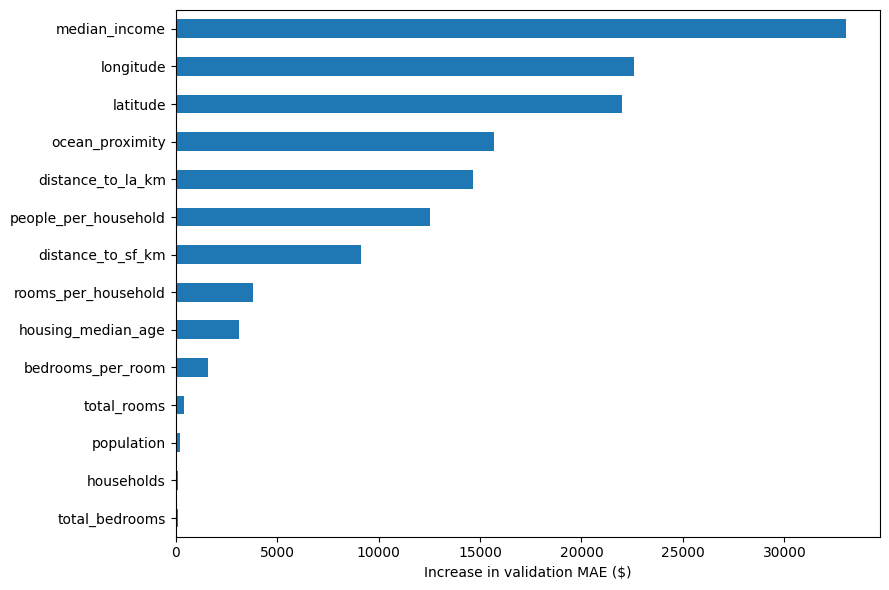

In [6]:
def neg_clipped_mae(model, data, target):
    predictions = model.predict(data).clip(max=CAP)
    return -mean_absolute_error(target, predictions)

importance_by_fold = []
for fit_rows, valid_rows in folds:
    model = clone(final_model)
    model.fit(X_train_features.iloc[fit_rows], y_train.iloc[fit_rows])
    result = permutation_importance(
        model, X_train_features.iloc[valid_rows], y_train.iloc[valid_rows],
        scoring=neg_clipped_mae, n_repeats=3, random_state=SEED,
    )
    importance_by_fold.append(result.importances_mean)
importance = pd.DataFrame(importance_by_fold, columns=X_train_features.columns).mean()
importance.sort_values().plot.barh(figsize=(9, 6))
plt.xlabel("Increase in validation MAE ($)")
plt.tight_layout()
plt.show()

## 7. テスト評価と誤差分析
選択済みの設定で学習側全体を使い、固定したテスト地区を評価する。比較表の全モデルは同じテスト地区で測る。

,Test MAE ($),Test R2
Model,,
Median baseline,87403.992,-0.050
Linear regression (9 features),50670.489,0.625
LightGBM (14 features),27845.633,0.842


,districts,MAE,mean_error
price_band,,,
Below 400k,3785,24342.57,6.62
400k–450k,97,65251.63,-49868.41
450k–cap,67,79461.85,-73447.97
At cap,179,62328.43,-62328.43


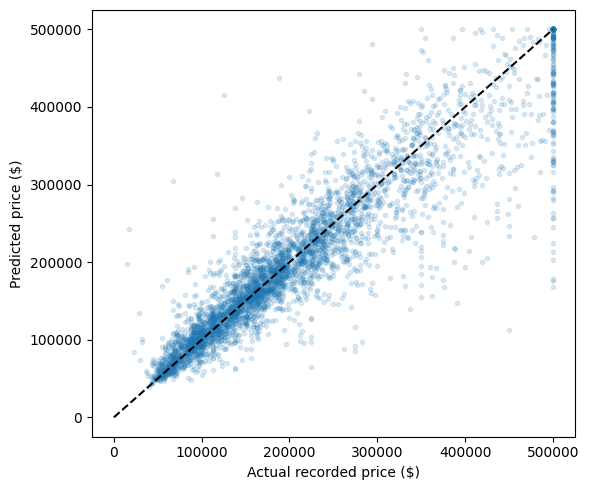

In [7]:
test_rows = []
for name, model, train_features, test_features in [
    ("Median baseline", DummyRegressor(strategy="median"), X_train, X_test),
    ("Linear regression (9 features)", linear_model, X_train, X_test),
    ("LightGBM (14 features)", final_model, X_train_features, X_test_features),
]:
    model.fit(train_features, y_train)
    predictions = model.predict(test_features)
    if name.startswith("LightGBM"):
        predictions = predictions.clip(max=CAP)
        test_pred = predictions
    test_rows.append({"Model": name, "Test MAE ($)": mean_absolute_error(y_test, predictions),
                      "Test R2": r2_score(y_test, predictions)})
display(pd.DataFrame(test_rows).set_index("Model").round(3))
errors = pd.DataFrame({"actual": y_test, "prediction": test_pred})
errors["error"] = errors["prediction"] - errors["actual"]
errors["absolute_error"] = errors["error"].abs()
errors["price_band"] = pd.cut(y_test, bins=[0, 400000, 450000, CAP, np.inf],
    labels=["Below 400k", "400k–450k", "450k–cap", "At cap"], right=False)
display(errors.groupby("price_band", observed=False).agg(
    districts=("error", "size"), MAE=("absolute_error", "mean"),
    mean_error=("error", "mean")).round(2))
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, test_pred, alpha=0.15, s=9)
ax.plot([0, CAP], [0, CAP], color="black", linestyle="--")
ax.set(xlabel="Actual recorded price ($)", ylabel="Predicted price ($)")
plt.tight_layout()
plt.show()

## 8. 結論と今後の課題
元の実行結果ではテストMAEが27,845.63ドルとなり、中央値予測の87,403.99ドルから約68%低下した。最終モデルは、比率・都市距離を含む14特徴量、LightGBMの絶対誤差目的関数、学習率0.1、400本、葉の上限63、最小50件、予測上限500,001ドルの構成とした。

上限地区では平均62,328.43ドルの過小予測が残った。全体MAEだけで性能を判断すると、この偏りを見落とす。上限を超える実際の価格を推定するには、上限処理のない価格データが必要になる。

今後は、予測する地域の範囲と許容誤差を具体化し、未観測地域で使う場合には地域単位の分割で検証する。モデルを追加改善する場合は学習側の交差検証で比較し、追加の独立データで最終性能を確認する。

### 出典と再現情報
データは Aurélien Géron の公開教材リポジトリから取得した。
https://github.com/ageron/handson-ml2/tree/master/datasets/housing

この清書では比率・距離計算を共通化し、確認用セル・重複コードを整理した。実験履歴表は過去の記録値であり、実行セルの出力は現在の環境で再計算した値である。

In [8]:
print({"numpy": np.__version__, "pandas": pd.__version__,
       "scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__})

{'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'lightgbm': '4.6.0'}
